# 01. State와 Node, Reducer
## 학습 목표
- `TypedDict`로 State를 정의하고 Node의 부분 업데이트를 설명한다.
- 기본 덮어쓰기와 Reducer의 리스트 누적을 비교한다.

**핵심 개념**: State는 Graph가 공유하는 현재 데이터, Node는 State를 읽고 변경할 필드만 반환하는 함수이다.  
Edge는 다음 Node를 정한다. 

## State 스키마 정의 및 이해
`greeting_node({"name": "민지", "message": "이전 인사"})`의 반환값에는 `name`이 있을까?  
Graph에 같은 입력을 주면 최종 State의 `name`은 어떻게 될까?

In [2]:
from typing import TypedDict
from langgraph.graph import START, END, StateGraph   # Node 정의

# State(공통 메모리 공간) 정의(State 구조 정의)
class MyState(TypedDict):
    name : str
    message : str

# Node 정의(node는 기본적으로 함수로 구성. 타입은 dict type. state로 식별.)
def greeting_node(state : MyState) -> dict:
    #변경할 필드만 반환한다.
    return {'message': f"안녕하세요, {state['name']}님"} # State를 읽어서 name만 update함.
    

# State 확인
initial = {"name": "민지", "message": "이전 인사"}
print("Python 함수 반환:", greeting_node(initial))  # 반환값에는 message만 담긴다.
print()
print("원본 딕셔너리:", initial)  # 원본은 변경되지 않고 그대로 유지된다.

Python 함수 반환: {'message': '안녕하세요, 민지님'}

원본 딕셔너리: {'name': '민지', 'message': '이전 인사'}


Python 함수는 새로운 부분 딕셔너리를 반환한다. 원본 딕셔너리를 직접 바꾸지 않는다.  
Graph는 반환된 필드만 기존 State에 반영한다.

## 그래프 설계(기본 Flow)

In [3]:
# StateGraph에 State 스키마(MyState)를 등록하여 Graph builder를 생성한다.

# SateGraph 객체 생성(이후 node들에서 State의 상태값 읽고 처리하려면 StateGraph 객체 생성시 만든 State를 넣어줘야 함)
builder = StateGraph(MyState)

# Node를 Graph에 등록(node 함수(greeting_node)를 식별할 식별자("greeting")도 설정 가능)
builder.add_node("greeting", greeting_node)

# Edge 연결(START -> greeting)
builder.add_edge(START, "greeting")

# Edge 연결(greeting -> END). 이렇게 하면 하나의 graph가 완성됨.
builder.add_edge("greeting", END)

# Graph 컴파일
graph = builder.compile()

## 그래프 그리기

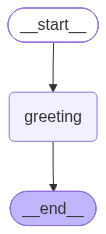

In [4]:
graph

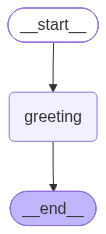

In [ ]:
# Graph 그리기
#from IPython.display import Image, display

# PNG 생성에 네트워크 등이 필요하면 Mermaid 텍스트로 대체한다.
#try:
#    display(Image(graph.get_graph().draw_mermaid_png()))
#except Exception as exc:
#    print("PNG 시각화 불가:", type(exc).__name__)
#    print(graph.get_graph().draw_mermaid())

In [5]:
initial = {"name": "Joy", "message": "이전 인사"}

result = graph.invoke(initial)    # invoke : 값 넣음. greeting이 실행됨. name은 바로 위에서 정의한 initial 값 그대로. message는 graph에서 update됨. 
# result는 그 시점에서의 공유하는 State 값의 최종 값이 된다. 내가 의도한대로 바뀌었는지 중간중간 확인할 것.
print("Graph 최종 State:", result)

# greeting_node가 반환한 message만 갱신되고, name은 그대로 유지되어야 한다.
assert result == {"name": "Joy", "message": "안녕하세요, Joy님"}  

# 평가. 메모리 상태값과 조건을 비교해서 통과해야만 다음 문장 실행됨. 의도한 대로 처리되고 있는지 평가. assert는 python 내장됨. 같지 않으면 error남.

Graph 최종 State: {'name': 'Joy', 'message': '안녕하세요, Joy님'}


## Reducer: 덮어쓰기와 누적
Reducer가 없는 `status`는 새 값으로 덮어쓴다.   
`history`는 `Annotated[..., operator.add]`에 따라 새 리스트를 뒤에 붙인다(누적). 
> Reducer는 Node들이 반환한 업데이트 값을 기존 State에 누적하거나 병합하는 역할을 한다.

목표 : 
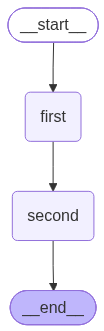

In [ ]:
from typing import Annotated
import operator

# status는 Reducer가 없어 새 값으로 덮어쓰고,
# history는 Annotated[list[str], operator.add]로 Reducer를 지정해 기존 리스트에 새 값을 누적한다.

# State 정의
class LogState(TypedDict):
    status : str
    history : Annotated[list[str], operator.add] # operator.add를 Reducer로 지정하면 기존 리스트에 새 리스트를 누적함.

# Node 정의
def first_node(state : LogState) -> dict: # 값 읽어옴. return type : dict
    return {'status' : '첫 단계', 'history' : ["첫 단계"]} # Log State update(history는 list로 들어옴)

# Node 정의
def second_node(state : LogState) -> dict: # 값 읽어옴. return type : dict
    return {'status' : '둘째 단계', 'history' : ["둘째 단계"]} # Log State update(history는 list로 들어옴)

# StateGraph에 State 스키마(LogState)를 등록하여 Graph builder 생성
builder = StateGraph(LogState)

# Node를 Graph에 등록(Node : 해당 node에서 State 값을 읽고 -> 처리하고 -> State 업데이트)
builder.add_node("first", first_node)
builder.add_node("second", second_node)

# Edge 연결(Edge : 실행의 흐름)
builder.add_edge(START, "first") # Start는 반드시 필요
builder.add_edge("first", 'second')
builder.add_edge('second', END) # End는 compile시 자동 생성되어 생략 가능하지만, 명시적으로 표시할 것. AI가 짠 경우 이거 확인할 것. loop문 등에서 문제가 될 수 있음.

# Graph 컴파일
log_graph = builder.compile()

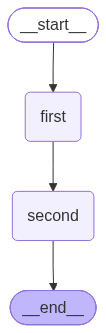

In [8]:
# Graph 그리기

log_graph

#from IPython.display import Image, display

# PNG 생성에 네트워크 등이 필요하면 Mermaid 텍스트로 대체한다.
#try:
#    display(Image(log_graph.get_graph().draw_mermaid_png()))
#except Exception as exc:
#    print("PNG 시각화 불가:", type(exc).__name__)
#    print(log_graph.get_graph().draw_mermaid())

Streaming : State의 중간값을 볼 수 있음. 디버깅 방식. invoke는 쭉 실행해서 마지막 state 값만 볼 수 있지만, update되는 state의 중간값 보려면 stream 써야 함.

In [9]:
# stream_mode="updates"는 최종 State가 아니라 각 Node가 반환한 변경분만 순서대로 보여준다.
for update in log_graph.stream({"status": "시작", "history": ["시작"]}, stream_mode="updates"):
    print("Node 업데이트:", update)

Node 업데이트: {'first': {'status': '첫 단계', 'history': ['첫 단계']}}
Node 업데이트: {'second': {'status': '둘째 단계', 'history': ['둘째 단계']}}


In [10]:
log_result = log_graph.invoke({"status": "시작", "history": ["시작"]})

print("최종 State:", log_result) # Reducer가 history에 진행 순서 갱신

# status는 마지막 값으로 덮어써지고, history는 시작값에 각 Node의 값이 순서대로 누적된다.
assert log_result == {"status": "둘째 단계", "history": ["시작", "첫 단계", "둘째 단계"]}

최종 State: {'status': '둘째 단계', 'history': ['시작', '첫 단계', '둘째 단계']}


`updates`는 각 Node가 반환한 변경분이다. 최종 State와 혼동하지 않는다. Reducer에 빈 리스트를 반환해도 기존 목록은 지워지지 않는다.

## 작은 수정 실습
`greeting_node`의 인사말을 "환영합니다, 이름님"으로 바꾸고 결과를 다시 예측·실행한다. 원래 코드를 유지하려면 새 함수를 만들어 같은 Graph 구성에 연결한다.

## 이해 확인
1. Node가 `{"message": "반갑습니다"}`만 반환하면 `name`은 어떻게 되는가?  
   **해설:** `name`은 그대로 유지되고 `message`만 덮어쓴다.
2. `second_node`가 `{"history": ["완료"]}`를 반환하면 기존 항목이 사라지는가?  
   **해설:** 사라지지 않는다. `operator.add`가 리스트를 이어 붙인다.

**핵심 정리:** Node는 State 전체가 아닌 업데이트를 반환하며, 필드별 Reducer가 그 업데이트의 반영 방식을 결정한다.